# Actividad 2: Preparación y Procesamiento de Datos
**Caso:** North Quay Gifts | **Conjunto de datos:** Online Retail II (`online_retail_II.csv`)
**Fase CRISP-DM:** Data Preparation

**Equipo:**
- Russel Emmanuel Ku Aguilar (2309131)
- Damian Nicolas Sanchez Novelo (2109134)
- Jonathan Abisai Velasco Martín (2309060)
- Ángel Rivaldo Canché Chuc (2309030)
- Bianca Alexandra Acosta Castellanos (2309001)

**Profesor:** Didier Omar Gamboa Angulo · Universidad Politécnica de Yucatán (UPY)

---
### Objetivo
Implementar dos estrategias de procesamiento sobre una **base común** trazable y comparar sus efectos en pedidos,
unidades e ingresos diarios:

- **Ruta A – Exclusión de registros:** solo compras válidas (sin prefijo `C`, `Quantity > 0`, `Price > 0`).
- **Ruta B – Reconocimiento de abonos:** las mismas compras de A más los abonos `C` con `Quantity < 0` y `Price > 0`,
  con su signo y en su fecha de registro, y una conciliación conservadora de esos abonos.

La libreta parte del archivo **original** (sin filtros previos) y asigna a cada línea un `SourceRow` estable, de modo que
cualquier exclusión puede reconstruirse. Todas las cifras del informe se generan aquí y se guardan en
`outputs/resultados_informe.json`.

In [1]:
import os, json
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'axes.edgecolor': '#333333', 'axes.linewidth': 0.8, 'font.size': 10})
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)
R = {}   # resultados que alimentan el informe
print('pandas', pd.__version__)

pandas 3.0.5


---
## I. Preparación inicial
### 1. Carga del original y clave `SourceRow`
Se lee el CSV con los identificadores como texto (`Invoice`, `StockCode`) para no perder ceros ni prefijos.
Si el CSV del repositorio es solo un puntero de Git LFS, se reconstruye con las dos hojas del Excel original
(*Year 2009-2010* y *Year 2010-2011*), concatenadas en su orden; el resultado es idéntico al CSV público
(1,067,371 líneas, mismos conteos de la Actividad 1).

`SourceRow` = número de línea de datos en el archivo original (1 = primera fila después del encabezado). Se asigna
**antes** de cualquier filtro y **no** participa en la búsqueda de duplicados.

In [2]:
CSV = '../Data/online_retail_II.csv'
XLSX = '../Data/online_retail_II.xlsx'
DTYPES = {'Invoice': str, 'StockCode': str, 'Description': str, 'Country': str}
ORIG_COLS = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

def es_puntero_lfs(path):
    with open(path, 'rb') as fh:
        return fh.read(60).startswith(b'version https://git-lfs')

if os.path.exists(CSV) and not es_puntero_lfs(CSV):
    raw = pd.read_csv(CSV, dtype=DTYPES, keep_default_na=True)
    fuente = CSV
else:
    try:
        hojas = pd.read_excel(XLSX, sheet_name=None, dtype=DTYPES, engine='calamine')
    except Exception:
        hojas = pd.read_excel(XLSX, sheet_name=None, dtype=DTYPES)
    raw = pd.concat(hojas.values(), ignore_index=True)
    raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate']).dt.strftime('%Y-%m-%d %H:%M:%S')
    fuente = XLSX + ' (2 hojas concatenadas)'

raw = raw[ORIG_COLS].copy()
original = raw.copy(deep=True)                       # copia intacta del original
raw.insert(0, 'SourceRow', np.arange(1, len(raw) + 1))
print('Fuente:', fuente)
print(f'Líneas originales: {len(raw):,} | columnas originales: {len(ORIG_COLS)}')
raw.head()

Fuente: ../Data/online_retail_II.csv
Líneas originales: 1,067,371 | columnas originales: 8


,SourceRow,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,1,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,2,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,3,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,4,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,5,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


### 2. Tipos: identificadores, fecha y medidas
- `Invoice` y `StockCode` se mantienen como **texto** (identificadores nominales).
- `InvoiceDate` se convierte a `datetime64` con `errors='coerce'` para contar fechas no interpretables.
- `Quantity` y `Price` se validan como numéricos con `errors='coerce'`. **Los precios no se redondean**; solo se
  redondean los resultados presentados.
- **Equivalencia documentada:** `Customer ID` (original) ≡ `CustomerID` (normalizado). Se guarda como entero
  anulable (`Int64`): `13085.0` → `13085`. Los clientes faltantes **permanecen nulos** (`<NA>`); no se crea ninguna
  clave compartida tipo “desconocido”.

In [3]:
df = raw.rename(columns={'Customer ID': 'CustomerID'}).copy()
df['InvoiceDateParsed'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
df['QuantityNum'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['PriceNum'] = pd.to_numeric(df['Price'], errors='coerce')
cid = pd.to_numeric(df['CustomerID'], errors='coerce')
assert ((cid.dropna() % 1) == 0).all(), 'Hay Customer ID no enteros'
df['CustomerID'] = cid.astype('Int64')

controles_tipo = pd.DataFrame({
    'Control': ['Invoice nulo', 'StockCode nulo', 'InvoiceDate no interpretable', 'Quantity no numérico',
                'Price no numérico', 'CustomerID nulo (se conserva)', 'Description nula (se conserva)'],
    'Líneas': [df['Invoice'].isna().sum(), df['StockCode'].isna().sum(), df['InvoiceDateParsed'].isna().sum(),
               df['QuantityNum'].isna().sum(), df['PriceNum'].isna().sum(), df['CustomerID'].isna().sum(),
               df['Description'].isna().sum()]})
print('Periodo original:', df['InvoiceDateParsed'].min(), '→', df['InvoiceDateParsed'].max())
controles_tipo

Periodo original: 2009-12-01 07:45:00 → 2011-12-09 12:50:00


,Control,Líneas
0,Invoice nulo,0
1,StockCode nulo,0
2,InvoiceDate no interpretable,0
3,Quantity no numérico,0
4,Price no numérico,0
5,CustomerID nulo (se conserva),243007
6,Description nula (se conserva),4382


### 3. Duplicados exactos
Se buscan duplicados exactos sobre las **ocho columnas originales** (sin `SourceRow`).

**Decisión:** conservar la primera aparición (menor `SourceRow`) y excluir las copias adicionales, igual en ambas rutas.
**Fundamento (Actividad 1):** las 34,335 copias repiten factura, producto, cantidad, precio, cliente y marca de tiempo al
minuto (p. ej., factura `489517`, `21491`, filas repetidas en el mismo minuto). El archivo no trae número de línea ni
evidencia de envío físico que distinga dos renglones legítimos de un doble registro; mantenerlas inflaría unidades e
ingresos. Es una decisión conservadora que se documenta y es reversible gracias a `SourceRow`.

In [4]:
dup_extra = df.duplicated(subset=[c if c != 'Customer ID' else 'CustomerID' for c in ORIG_COLS], keep='first')
# grupos con al menos una copia
dup_any = df.duplicated(subset=[c if c != 'Customer ID' else 'CustomerID' for c in ORIG_COLS], keep=False)
n_dup_extra = int(dup_extra.sum())
n_grupos = int(df[dup_any].groupby(['Invoice','StockCode','Description','Quantity','InvoiceDate','Price','CustomerID','Country'], dropna=False).ngroups)
print(f'Copias adicionales excluidas: {n_dup_extra:,}')
print(f'Grupos de líneas duplicadas: {n_grupos:,} (se retiene 1 línea por grupo)')
print(f'Líneas involucradas en duplicados: {int(dup_any.sum()):,}')
df[dup_any].sort_values('SourceRow').head(6)[['SourceRow'] + [c for c in df.columns if c in ORIG_COLS or c=='CustomerID']]

Copias adicionales excluidas: 34,335
Grupos de líneas duplicadas: 32,907 (se retiene 1 línea por grupo)
Líneas involucradas en duplicados: 67,242


,SourceRow,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
362,363,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
363,364,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
365,366,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
367,368,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329,United Kingdom
368,369,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329,United Kingdom
371,372,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom


### 4. Otras exclusiones comunes y base común
Se excluyen (por separado de los duplicados) las líneas con fecha no interpretable, `Quantity`/`Price` no numéricos o
identificadores de factura/producto nulos. **Las líneas sin cliente se conservan**, porque sus campos transaccionales
son utilizables para el resumen global; no se imputan clientes ni descripciones.

In [5]:
excl_comun = pd.Series(pd.NA, index=df.index, dtype='object')
excl_comun[dup_extra] = 'Duplicado exacto (copia adicional)'
reglas = [
    (df['InvoiceDateParsed'].isna(), 'Fecha no interpretable'),
    (df['QuantityNum'].isna(), 'Quantity no numérica'),
    (df['PriceNum'].isna(), 'Price no numérico'),
    (df['Invoice'].isna() | df['StockCode'].isna(), 'Identificador nulo'),
]
otras = {}
for mask, motivo in reglas:
    otras[motivo] = int((mask & ~dup_extra).sum())
    excl_comun[mask & excl_comun.isna()] = motivo
df['CommonExclusion'] = excl_comun

base = df[df['CommonExclusion'].isna()].copy()
base['InvoiceDate'] = base['InvoiceDateParsed']
base['Quantity'] = base['QuantityNum'].astype('int64')
base['Price'] = base['PriceNum']
base = base.drop(columns=['InvoiceDateParsed', 'QuantityNum', 'PriceNum', 'CommonExclusion'])
base['Date'] = base['InvoiceDate'].dt.normalize()
base['LineAmount'] = base['Quantity'] * base['Price']
base['IsC'] = base['Invoice'].str.upper().str.startswith('C')

N_ORIG, N_BASE = len(df), len(base)
print('Otras exclusiones comunes:', otras)
print(f'Líneas originales {N_ORIG:,} − copias {n_dup_extra:,} − otras {sum(otras.values()):,} = base común {N_BASE:,}')
assert N_ORIG - n_dup_extra - sum(otras.values()) == N_BASE
print('Clientes nulos conservados en la base:', int(base['CustomerID'].isna().sum()))

R['control_inicial'] = dict(fuente=fuente, periodo_ini=str(df['InvoiceDateParsed'].min()), periodo_fin=str(df['InvoiceDateParsed'].max()),
    n_orig=N_ORIG, n_dup_extra=n_dup_extra, n_grupos_dup=n_grupos, n_lineas_en_dup=int(dup_any.sum()), otras=otras, n_base=N_BASE,
    clientes_nulos_base=int(base['CustomerID'].isna().sum()))

Otras exclusiones comunes: {'Fecha no interpretable': 0, 'Quantity no numérica': 0, 'Price no numérico': 0, 'Identificador nulo': 0}
Líneas originales 1,067,371 − copias 34,335 − otras 0 = base común 1,033,036
Clientes nulos conservados en la base: 235151


---
## II. Estrategias de procesamiento
### Ruta A – Exclusión de registros
Desde la base común se excluyen: facturas con prefijo `C`, líneas con `Quantity ≤ 0` y líneas con `Price ≤ 0`.
Se informan los conteos por condición (superpuestos) y el total excluido como **unión** (cada línea una sola vez).
**Prioridad del motivo principal:** (1) prefijo `C` → (2) `Quantity ≤ 0` → (3) `Price ≤ 0`.

In [6]:
cA_C = base['IsC']
cA_Q = base['Quantity'] <= 0
cA_P = base['Price'] <= 0
exclA = cA_C | cA_Q | cA_P

motivoA = np.select([cA_C, cA_Q, cA_P], ['Prefijo C', 'Quantity <= 0', 'Price <= 0'], default='Compra válida')
base['RouteA_Status'] = motivoA

purchases = base[~exclA].copy()
purchases['MovementType'] = 'Purchase'
assert (purchases['Quantity'] > 0).all() and (purchases['Price'] > 0).all() and (~purchases['IsC']).all()

condA = pd.DataFrame({
    'Condición (superpuesta)': ['Invoice con prefijo C', 'Quantity <= 0', 'Price <= 0', 'Total excluido (unión, sin doble conteo)'],
    'Líneas': [int(cA_C.sum()), int(cA_Q.sum()), int(cA_P.sum()), int(exclA.sum())]})
display(condA)
print('Motivo principal asignado (disjunto):')
display(base['RouteA_Status'].value_counts().rename_axis('Motivo').to_frame('Líneas'))
print('Superposiciones:  C∧Q<=0 =', int((cA_C & cA_Q).sum()), '| Q<=0∧P<=0 =', int((cA_Q & cA_P).sum()), '| C∧P<=0 =', int((cA_C & cA_P).sum()))
nA_keep, nA_excl = len(purchases), int(exclA.sum())
assert nA_keep + nA_excl == N_BASE
print(f'Ruta A: conservadas {nA_keep:,} + excluidas {nA_excl:,} = {nA_keep + nA_excl:,} = base común')

,Condición (superpuesta),Líneas
0,Invoice con prefijo C,19104
1,Quantity <= 0,22496
2,Price <= 0,6019
3,"Total excluido (unión, sin doble conteo)",25123


Motivo principal asignado (disjunto):


,Líneas
Motivo,
Compra válida,1007913
Prefijo C,19104
Quantity <= 0,3393
Price <= 0,2626


Superposiciones:  C∧Q<=0 = 19103 | Q<=0∧P<=0 = 3393 | C∧P<=0 = 0
Ruta A: conservadas 1,007,913 + excluidas 25,123 = 1,033,036 = base común


### Ruta B – Reconocimiento de abonos
B conserva **las mismas compras válidas de A** y añade las líneas `C` con `Quantity < 0` y `Price > 0` como **abonos
documentados**, con signo negativo y en su fecha de registro (aunque no se identifique la factura de origen).

Fuera del resultado comercial quedan como **excepciones**:
- líneas `C` con `Quantity ≥ 0` o `Price ≤ 0`;
- **negativos sin `C`** (`Quantity < 0` sin prefijo), que se investigan abajo;
- líneas sin `C` con `Quantity > 0` y `Price ≤ 0` (precio no positivo, igual que en A).

**Prioridad del motivo principal en B:** (1) compra válida → (2) abono `C` reconocido → (3) excepción `C` →
(4) negativo sin `C` → (5) precio no positivo sin `C`.

In [7]:
is_credit = base['IsC'] & (base['Quantity'] < 0) & (base['Price'] > 0)
exc_C = base['IsC'] & ~is_credit
neg_noC = ~base['IsC'] & (base['Quantity'] < 0)
zero_noC = ~base['IsC'] & (base['Quantity'] == 0)
price_noC = ~base['IsC'] & (base['Quantity'] > 0) & (base['Price'] <= 0)

statusB = np.select([~exclA, is_credit, exc_C, neg_noC, zero_noC, price_noC],
                    ['Compra válida', 'Abono C reconocido', 'Excepción C (Q>=0 o P<=0)', 'Negativo sin C', 'Cantidad cero sin C', 'Precio no positivo sin C'],
                    default='Sin clasificar')
base['RouteB_Status'] = statusB
assert (base['RouteB_Status'] != 'Sin clasificar').all()

credits = base[is_credit].copy()
credits['MovementType'] = 'Credit'
routeB = pd.concat([purchases, credits]).sort_values('SourceRow')
nB_keep = len(routeB); nB_excl = N_BASE - nB_keep
assert nB_keep + nB_excl == N_BASE
display(base['RouteB_Status'].value_counts().rename_axis('Estado B').to_frame('Líneas'))
print(f'Ruta B: conservadas {nB_keep:,} + excluidas {nB_excl:,} = {N_BASE:,} = base común')
print('Excepciones C:')
display(base[exc_C][['SourceRow','Invoice','StockCode','Description','Quantity','Price','CustomerID','InvoiceDate']])

,Líneas
Estado B,
Compra válida,1007913
Abono C reconocido,19103
Negativo sin C,3393
Precio no positivo sin C,2626
Excepción C (Q>=0 o P<=0),1


Ruta B: conservadas 1,027,016 + excluidas 6,020 = 1,033,036 = base común
Excepciones C:


,SourceRow,Invoice,StockCode,Description,Quantity,Price,CustomerID,InvoiceDate
76799,76800,C496350,M,Manual,1,373.57,<NA>,2010-02-01 08:24:00


#### Investigación de los negativos sin `C`
Se revisan precio, descripción y cliente para decidir si existe evidencia de devolución de venta.

In [8]:
neg = base[neg_noC]
inv_neg = pd.DataFrame({
    'Indicador': ['Líneas', 'Facturas distintas', 'Unidades (suma con signo)', 'Líneas con Price = 0', 'Líneas con Price > 0',
                  'Líneas con cliente identificado', 'Líneas sin descripción', 'Importe Quantity×Price (GBP)'],
    'Valor': [len(neg), neg['Invoice'].nunique(), int(neg['Quantity'].sum()), int((neg['Price'] == 0).sum()), int((neg['Price'] > 0).sum()),
              int(neg['CustomerID'].notna().sum()), int(neg['Description'].isna().sum()), round(float(neg['LineAmount'].sum()), 2)]})
display(inv_neg)
print('Descripciones más frecuentes:')
display(neg['Description'].fillna('<nula>').value_counts().head(12).rename_axis('Description').to_frame('Líneas'))
neg.sort_values('Quantity').head(5)[['SourceRow','Invoice','StockCode','Description','Quantity','Price','CustomerID','InvoiceDate']]

,Indicador,Valor
0,Líneas,3393.0
1,Facturas distintas,3393.0
2,Unidades (suma con signo),-569314.0
3,Líneas con Price = 0,3393.0
4,Líneas con Price > 0,0.0
5,Líneas con cliente identificado,0.0
6,Líneas sin descripción,2633.0
7,Importe Quantity×Price (GBP),0.0


Descripciones más frecuentes:


,Líneas
Description,
<nula>,2633
check,121
damages,83
?,81
damaged,78
missing,27
sold as set on dotcom,20
Damaged,17
smashed,9


,SourceRow,Invoice,StockCode,Description,Quantity,Price,CustomerID,InvoiceDate
750990,750991,556690,23005,printing smudges/thrown away,-9600,0.0,<NA>,2011-06-14 10:37:00
750991,750992,556691,23005,printing smudges/thrown away,-9600,0.0,<NA>,2011-06-14 10:37:00
303996,303997,519017,22759,NaN,-9600,0.0,<NA>,2010-08-13 09:14:00
156488,156489,504311,22197,NaN,-9200,0.0,<NA>,2010-04-12 14:39:00
750989,750990,556687,23003,Printing smudges/thrown away,-9058,0.0,<NA>,2011-06-14 10:36:00


**Tratamiento:** todos los negativos sin `C` tienen `Price = 0`, ningún cliente y descripciones de ajuste interno
(*check, damages, ?, missing, smashed, thrown away*) o nulas. No hay precio que valorar ni cliente al que abonar, por lo
que **no hay evidencia de devolución de venta**: quedan fuera del resultado comercial en ambas rutas y su impacto
monetario es £0. No se convierten en ventas positivas. Se interpretan como posibles ajustes de inventario (hipótesis
que requeriría confirmación de almacén).

In [9]:
neg_ctrl = dict(lineas=len(neg), facturas=int(neg['Invoice'].nunique()), unidades=int(neg['Quantity'].sum()),
                price0=int((neg['Price'] == 0).sum()), con_cliente=int(neg['CustomerID'].notna().sum()),
                sin_desc=int(neg['Description'].isna().sum()),
                top_desc=neg['Description'].dropna().value_counts().head(6).to_dict())
R['rutas'] = dict(
    A=dict(conservadas=nA_keep, excluidas=nA_excl, compras=len(purchases), abonos=0,
           cond_C=int(cA_C.sum()), cond_Q=int(cA_Q.sum()), cond_P=int(cA_P.sum()),
           motivo=base['RouteA_Status'].value_counts().to_dict()),
    B=dict(conservadas=nB_keep, excluidas=nB_excl, compras=len(purchases), abonos=len(credits),
           abonos_facturas=int(credits['Invoice'].nunique()), estados=base['RouteB_Status'].value_counts().to_dict()),
    exc_C=int(exc_C.sum()), exc_C_detalle=base[exc_C][['Invoice','StockCode','Quantity','Price']].astype(str).to_dict('records'),
    neg_noC=neg_ctrl, precio_no_pos_sinC=int(price_noC.sum()), c_total=int(base['IsC'].sum()))

ctrl_rutas = pd.DataFrame({
    'Control de la ruta': ['Líneas conservadas', 'Líneas excluidas de la base común', 'Compras válidas conservadas',
                           'Abonos C negativos reconocidos', 'Excepciones C y negativos sin C'],
    'A': [nA_keep, nA_excl, len(purchases), 0, f'{int(exc_C.sum())} + {len(neg):,} (excluidas)'],
    'B': [nB_keep, nB_excl, len(purchases), len(credits), f'{int(exc_C.sum())} + {len(neg):,} (fuera del resultado)']})
ctrl_rutas

,Control de la ruta,A,B
0,Líneas conservadas,1007913,1027016
1,Líneas excluidas de la base común,25123,6020
2,Compras válidas conservadas,1007913,1007913
3,Abonos C negativos reconocidos,0,19103
4,Excepciones C y negativos sin C,"1 + 3,393 (excluidas)","1 + 3,393 (fuera del resultado)"


---
### Investigación de correspondencias de los abonos (conciliación conservadora)
**Reglas reproducibles**
1. **Llave:** mismo `CustomerID` identificado, mismo `StockCode` y **mismo precio unitario exacto** (tolerancia 0). Se
   comparan los valores registrados (2–3 decimales) sin redondear; un precio distinto puede corresponder a otra
   condición comercial, por lo que no se acepta como evidencia. Quitar la `C` de `Invoice` **no** se usa como llave.
2. **Agregación de compras:** las compras válidas se agrupan por `(CustomerID, StockCode, Price, Invoice)` →
   unidades de la factura y su hora de cierre (= última hora de **toda** la factura). Así no se cruza detalle contra
   detalle. La compra candidata debe estar **completa antes** del abono: `cierre_factura < InvoiceDate_abono`.
3. **Capacidad:** una factura es candidata si su saldo disponible ≥ |Quantity| del abono (se admiten devoluciones
   parciales). Los abonos se recorren en orden cronológico (`InvoiceDate`, `SourceRow`); al aceptar un vínculo se
   descuentan esas unidades del saldo.
4. **Aceptación:** se concilia cuando hay **una sola** candidata y su saldo no está comprometido por un abono anterior
   pendiente. Es **ambigua** si hay varias candidatas, o si la única candidata ya figura entre las candidatas de un abono
   ambiguo previo de la misma llave (su asignación depende de resolver ese abono). No se elige por cercanía temporal.
5. **No conciliada:** sin cliente; sin compra previa del cliente para ese producto (p. ej., venta anterior al inicio del
   archivo); compras previas solo con precio diferente; unidades repartidas en varias facturas (no se fuerza un vínculo
   múltiple); o capacidad previa insuficiente.

Cada vínculo aceptado es una **propuesta analítica**: el archivo no trae referencia explícita a la venta cancelada.

In [10]:
inv_cierre = base.groupby('Invoice')['InvoiceDate'].max()
pg = (purchases[purchases['CustomerID'].notna()]
      .groupby(['CustomerID', 'StockCode', 'Price', 'Invoice'], as_index=False)
      .agg(Units=('Quantity', 'sum'), Lineas=('SourceRow', 'size')))
pg['InvoiceClose'] = pg['Invoice'].map(inv_cierre)
print(f'Grupos factura-cliente-producto-precio: {len(pg):,} (desde {purchases["CustomerID"].notna().sum():,} líneas de compra con cliente)')

capacidad = defaultdict(list)        # llave -> [factura, cierre, unidades, saldo]
for r in pg.itertuples(index=False):
    capacidad[(int(r.CustomerID), r.StockCode, r.Price)].append([r.Invoice, r.InvoiceClose, int(r.Units), int(r.Units)])
primera_compra = pg.groupby(['CustomerID', 'StockCode'])['InvoiceClose'].min()
primera_compra.index = [(int(c), s) for c, s in primera_compra.index]
primera_compra = primera_compra.to_dict()

pendientes = defaultdict(set)        # llave -> facturas comprometidas por abonos ambiguos
audit = []
for r in credits.sort_values(['InvoiceDate', 'SourceRow']).itertuples(index=False):
    q = -int(r.Quantity)
    rec = dict(SourceRow=r.SourceRow, Invoice=r.Invoice, CustomerID=r.CustomerID, StockCode=r.StockCode,
               Description=r.Description, Price=r.Price, InvoiceDate=r.InvoiceDate, ReturnedUnits=q,
               NCandidates=0, LinkedInvoice=pd.NA, LinkedInvoiceClose=pd.NaT, LinkedInvoiceUnits=pd.NA,
               PartialReturn=False, Status=None, Reason=None)
    if pd.isna(r.CustomerID):
        rec.update(Status='No conciliada', Reason='Sin cliente identificado')
    else:
        key = (int(r.CustomerID), r.StockCode, r.Price)
        previas = [c for c in capacidad.get(key, []) if c[1] < r.InvoiceDate]
        cand = [c for c in previas if c[3] >= q]
        rec['NCandidates'] = len(cand)
        if len(cand) == 1 and cand[0][0] not in pendientes[key]:
            c = cand[0]; c[3] -= q
            rec.update(Status='Conciliada', Reason='Única factura previa con saldo suficiente', LinkedInvoice=c[0],
                       LinkedInvoiceClose=c[1], LinkedInvoiceUnits=c[2], PartialReturn=q < c[2])
        elif len(cand) == 1:
            pendientes[key].add(cand[0][0])
            rec.update(Status='Ambigua', Reason='Única candidata con saldo comprometido por un abono anterior pendiente')
        elif len(cand) > 1:
            pendientes[key].update(c[0] for c in cand)
            rec.update(Status='Ambigua', Reason='Varias facturas candidatas')
        else:
            pc = primera_compra.get((key[0], key[1]))
            if pc is None or pc >= r.InvoiceDate:
                motivo = 'Sin compra previa del cliente para ese producto'
            elif not previas:
                motivo = 'Compras previas solo con precio diferente'
            elif sum(c[3] for c in previas) >= q:
                motivo = 'Unidades repartidas en varias facturas (no se fuerza)'
            else:
                motivo = 'Saldo previo insuficiente'
            rec.update(Status='No conciliada', Reason=motivo)
    audit.append(rec)

audit = pd.DataFrame(audit)
assert len(audit) == len(credits)
orden = ['Conciliada', 'Ambigua', 'No conciliada']
res_conc = (audit.groupby('Status').agg(Lineas=('SourceRow', 'size'), FacturasC=('Invoice', 'nunique'),
            Unidades=('ReturnedUnits', 'sum'), ImporteGBP=('Price', lambda s: 0)).reindex(orden).fillna(0))
res_conc['ImporteGBP'] = audit.assign(Imp=audit['ReturnedUnits'] * audit['Price']).groupby('Status')['Imp'].sum().reindex(orden).fillna(0).round(2)
res_conc['% líneas'] = (100 * res_conc['Lineas'] / len(audit)).round(2)
display(res_conc)
print('Suma de líneas por estado =', int(res_conc['Lineas'].sum()), '| abonos examinados =', len(credits))
assert int(res_conc['Lineas'].sum()) == len(credits)
print('Facturas C distintas en total:', audit['Invoice'].nunique(), '(una factura puede tener líneas en varios estados)')
print('Facturas C con líneas en más de un estado:', int((audit.groupby('Invoice')['Status'].nunique() > 1).sum()))
display(audit.groupby(['Status', 'Reason']).size().rename('Líneas').to_frame())

Grupos factura-cliente-producto-precio: 769,031 (desde 779,425 líneas de compra con cliente)


,Lineas,FacturasC,Unidades,ImporteGBP,% líneas
Status,,,,,
Conciliada,9827,4935,368121,588174.90,51.44
Ambigua,5393,2829,60440,132723.50,28.23
No conciliada,3883,2351,48259,741525.78,20.33


Suma de líneas por estado = 19103 | abonos examinados = 19103
Facturas C distintas en total: 8291 (una factura puede tener líneas en varios estados)
Facturas C con líneas en más de un estado: 1614


Líneas
Status        Reason                                                    
Ambigua       Varias facturas candidatas                            5381
              Única candidata con saldo comprometido por un a...      12
Conciliada    Única factura previa con saldo suficiente             9827
No conciliada Compras previas solo con precio diferente              846
              Saldo previo insuficiente                              172
              Sin cliente identificado                               713
              Sin compra previa del cliente para ese producto       2060
              Unidades repartidas en varias facturas (no se f...      92

#### Casos ilustrativos (uno por estado y una devolución parcial)

In [11]:
cols_aud = ['SourceRow','Invoice','CustomerID','StockCode','Description','Price','InvoiceDate','ReturnedUnits','NCandidates','LinkedInvoice','LinkedInvoiceUnits','PartialReturn','Status','Reason']
ej = {}
ej['Conciliada (total)'] = audit[(audit.Status == 'Conciliada') & ~audit.PartialReturn].iloc[0]
ej['Conciliada (parcial)'] = audit[(audit.Status == 'Conciliada') & audit.PartialReturn].iloc[0]
ej['Ambigua'] = audit[(audit.Status == 'Ambigua') & (audit.Reason == 'Varias facturas candidatas')].iloc[0]
ej['No conciliada (con cliente)'] = audit[(audit.Status == 'No conciliada') & audit.CustomerID.notna()].iloc[0]
ej['No conciliada (sin cliente)'] = audit[(audit.Status == 'No conciliada') & audit.CustomerID.isna()].iloc[0]
casos = pd.DataFrame(ej).T[cols_aud]
display(casos)

# Evidencia: compras candidatas del caso ambiguo y del parcial
for etiqueta in ['Conciliada (parcial)', 'Ambigua']:
    e = ej[etiqueta]
    k = purchases[(purchases.CustomerID == e.CustomerID) & (purchases.StockCode == e.StockCode) & (purchases.Price == e.Price) & (purchases.InvoiceDate < e.InvoiceDate)]
    print(f'\n{etiqueta}: abono {e.Invoice} ({e.InvoiceDate}) devuelve {e.ReturnedUnits} u. de {e.StockCode} a £{e.Price}; compras previas misma llave:')
    display(k.groupby('Invoice').agg(Cierre=('InvoiceDate', 'max'), Unidades=('Quantity', 'sum')))
R['conciliacion'] = dict(
    tabla={s: dict(lineas=int(res_conc.loc[s, 'Lineas']), facturas=int(res_conc.loc[s, 'FacturasC']), unidades=int(res_conc.loc[s, 'Unidades']),
                   importe=float(res_conc.loc[s, 'ImporteGBP']), pct=float(res_conc.loc[s, '% líneas'])) for s in orden},
    motivos=audit.groupby(['Status', 'Reason']).size().rename('n').reset_index().to_dict('records'),
    parciales=int(audit.PartialReturn.sum()), facturas_C_total=int(audit['Invoice'].nunique()),
    facturas_multi_estado=int((audit.groupby('Invoice')['Status'].nunique() > 1).sum()),
    grupos_compra=len(pg),
    casos={k: {c: str(v[c]) for c in cols_aud} for k, v in ej.items()})

,SourceRow,Invoice,CustomerID,StockCode,Description,Price,InvoiceDate,ReturnedUnits,NCandidates,LinkedInvoice,LinkedInvoiceUnits,PartialReturn,Status,Reason
Conciliada (total),1354,C489563,13526,90088,CRYSTAL KEY+LOCK PHONE CHARM,0.85,2009-12-01 13:09:00,24,1,489560,24,False,Conciliada,Única factura previa con saldo suficiente
Conciliada (parcial),1163,C489554,13767,85042,ANTIQUE LILY FAIRY LIGHTS,4.25,2009-12-01 12:43:00,3,1,489465,24,True,Conciliada,Única factura previa con saldo suficiente
Ambigua,1377,C489565,13526,90125A,PINK BERTIE GLASS BEAD BAG CHARM,2.1,2009-12-01 13:14:00,12,2,NaN,<NA>,False,Ambigua,Varias facturas candidatas
No conciliada (con cliente),179,C489449,16321,22087,PAPER BUNTING WHITE LACE,2.95,2009-12-01 10:33:00,12,0,NaN,<NA>,False,No conciliada,Sin compra previa del cliente para ese producto
No conciliada (sin cliente),5898,C489859,<NA>,M,Manual,69.57,2009-12-02 14:45:00,1,0,NaN,<NA>,False,No conciliada,Sin cliente identificado



Conciliada (parcial): abono C489554 (2009-12-01 12:43:00) devuelve 3 u. de 85042 a £4.25; compras previas misma llave:


,Cierre,Unidades
Invoice,,
489465,2009-12-01 10:52:00,24



Ambigua: abono C489565 (2009-12-01 13:14:00) devuelve 12 u. de 90125A a £2.1; compras previas misma llave:


,Cierre,Unidades
Invoice,,
489560,2009-12-01 12:56:00,12
489564,2009-12-01 13:13:00,12


In [12]:
audit_out = audit.copy()
audit_out['InvoiceDate'] = audit_out['InvoiceDate'].dt.strftime('%Y-%m-%d %H:%M:%S')
audit_out['LinkedInvoiceClose'] = pd.to_datetime(audit_out['LinkedInvoiceClose']).dt.strftime('%Y-%m-%d %H:%M:%S')
audit_out.to_csv('outputs/auditoria_conciliacion_abonos.csv', index=False)
print('Exportado outputs/auditoria_conciliacion_abonos.csv', audit_out.shape)

Exportado outputs/auditoria_conciliacion_abonos.csv (19103, 15)


---
## III. Construcción de indicadores diarios
`LineAmount = Quantity × Price` (GBP) y `Date = InvoiceDate` sin hora. Una fila por fecha y ruta:

| Campo | Ruta A | Ruta B |
|---|---|---|
| TotalOrders | facturas distintas de compra válida | las mismas facturas de compra; los `C` no son pedidos |
| TotalUnits | suma de `Quantity` positiva | suma con signo de compras y abonos |
| Revenue | suma de `LineAmount` de compras | suma con signo de compras y abonos |

Las fechas se alinean con la **unión de fechas observadas en la base común** (no el calendario completo); si una fecha
no tiene movimientos elegibles en una ruta, su agregado es cero.

In [13]:
fechas_base = pd.DatetimeIndex(sorted(base['Date'].unique()), name='Date')

def diaria(mov):
    g = mov.groupby('Date')
    out = pd.DataFrame({
        'TotalOrders': mov[mov['MovementType'] == 'Purchase'].groupby('Date')['Invoice'].nunique(),
        'TotalUnits': g['Quantity'].sum(),
        'Revenue': g['LineAmount'].sum()})
    out = out.reindex(fechas_base).fillna(0)
    out['TotalOrders'] = out['TotalOrders'].astype(int); out['TotalUnits'] = out['TotalUnits'].astype(int)
    return out

dA, dB = diaria(purchases), diaria(routeB)
print('Fechas observadas en la base común:', len(fechas_base), '|', fechas_base.min().date(), '→', fechas_base.max().date())
for nombre, d, mov in [('A', dA, purchases), ('B', dB, routeB)]:
    print(f'\nRuta {nombre}: filas {len(d)}, fechas distintas {d.index.nunique()}')
    print('  unidades diario vs transaccional:', int(d.TotalUnits.sum()), int(mov.Quantity.sum()))
    print('  ingresos diario vs transaccional:', round(d.Revenue.sum(), 2), round(mov.LineAmount.sum(), 2), '| dif =', d.Revenue.sum() - mov.LineAmount.sum())
    print('  días sin movimientos elegibles (agregado = 0):', int(((d.TotalOrders == 0) & (d.TotalUnits == 0)).sum()))

Fechas observadas en la base común: 604 | 2009-12-01 → 2011-12-09

Ruta A: filas 604, fechas distintas 604
  unidades diario vs transaccional: 11205148 11205148
  ingresos diario vs transaccional: 20476260.45 20476260.45 | dif = 0.0
  días sin movimientos elegibles (agregado = 0): 0

Ruta B: filas 604, fechas distintas 604
  unidades diario vs transaccional: 10728328 10728328
  ingresos diario vs transaccional: 19013836.27 19013836.27 | dif = 0.0
  días sin movimientos elegibles (agregado = 0): 0


In [14]:
multi_fecha = {k: int((m.groupby('Invoice')['Date'].nunique() > 1).sum()) for k, m in [('A', purchases), ('B', routeB)]}
multi_hora = {k: int((m.groupby('Invoice')['InvoiceDate'].nunique() > 1).sum()) for k, m in [('A', purchases), ('B', routeB)]}
print('Facturas en más de una fecha:', multi_fecha, '| facturas con más de una hora (mismo día):', multi_hora)
print('Pedidos: suma diaria A =', dA.TotalOrders.sum(), '| facturas de compra distintas (global) =', purchases['Invoice'].nunique())
assert dA.TotalOrders.sum() == dB.TotalOrders.sum() == purchases['Invoice'].nunique()
assert np.isclose(dA.Revenue.sum(), purchases.LineAmount.sum()) and np.isclose(dB.Revenue.sum(), routeB.LineAmount.sum())

# Días de la base sin compras, solo abonos (pueden quedar negativos en B)
solo_abonos = dB[(dB.TotalOrders == 0) & (dB.TotalUnits != 0)]
print('Días con abonos y sin compras:', len(solo_abonos))
display(solo_abonos)
print('Días de la base sin ningún movimiento elegible en ninguna ruta:')
display(dB[(dB.TotalOrders == 0) & (dB.TotalUnits == 0)])

Facturas en más de una fecha: {'A': 0, 'B': 0} | facturas con más de una hora (mismo día): {'A': 82, 'B': 83}
Pedidos: suma diaria A = 40077 | facturas de compra distintas (global) = 40077
Días con abonos y sin compras: 0


,TotalOrders,TotalUnits,Revenue
Date,,,


Días de la base sin ningún movimiento elegible en ninguna ruta:


,TotalOrders,TotalUnits,Revenue
Date,,,


In [15]:
mes = lambda d: d.index.to_period('M')
cobertura = base.groupby(base['Date'].dt.to_period('M'))['Date'].agg(['min', 'max', 'nunique'])
print('Primer mes:', cobertura.iloc[0].to_dict())
print('Último mes:', cobertura.iloc[-1].to_dict())
print('Ruta A – primeras y últimas cinco filas'); display(dA.head()); display(dA.tail())
print('Ruta B – primeras y últimas cinco filas'); display(dB.head()); display(dB.tail())

Primer mes: {'min': Timestamp('2009-12-01 00:00:00'), 'max': Timestamp('2009-12-23 00:00:00'), 'nunique': 21}
Último mes: {'min': Timestamp('2011-12-01 00:00:00'), 'max': Timestamp('2011-12-09 00:00:00'), 'nunique': 8}
Ruta A – primeras y últimas cinco filas


,TotalOrders,TotalUnits,Revenue
Date,,,
2009-12-01,119,26098,54351.23
2009-12-02,115,31804,63172.58
2009-12-03,124,49221,73972.45
2009-12-04,89,21210,40582.32
2009-12-05,30,5119,9803.05


,TotalOrders,TotalUnits,Revenue
Date,,,
2011-12-05,127,44497,88620.84
2011-12-06,115,30377,56558.83
2011-12-07,106,41789,75315.55
2011-12-08,120,35010,82371.55
2011-12-09,44,93950,200918.98


Ruta B – primeras y últimas cinco filas


,TotalOrders,TotalUnits,Revenue
Date,,,
2009-12-01,119,25468,53010.76
2009-12-02,115,31538,62583.66
2009-12-03,124,46819,68027.59
2009-12-04,89,21104,40195.80
2009-12-05,30,5119,9803.05


,TotalOrders,TotalUnits,Revenue
Date,,,
2011-12-05,127,44372,57630.20
2011-12-06,115,29282,54109.39
2011-12-07,106,41681,74952.61
2011-12-08,120,34371,81294.33
2011-12-09,44,12920,32129.91


In [16]:
def exportable(d, ruta=None):
    o = d.reset_index()
    o['Date'] = o['Date'].dt.strftime('%Y-%m-%d')
    if ruta: o.insert(0, 'Route', ruta)
    return o
comp = pd.concat([exportable(dA, 'A'), exportable(dB, 'B')], ignore_index=True)[['Route', 'Date', 'TotalOrders', 'TotalUnits', 'Revenue']]
comp.to_csv('outputs/indicadores_diarios_comparacion.csv', index=False)
print('Exportado outputs/indicadores_diarios_comparacion.csv', comp.shape)
R['diarios'] = dict(
    fechas=len(fechas_base), ini=str(fechas_base.min().date()), fin=str(fechas_base.max().date()),
    A=dict(filas=len(dA), unid_d=int(dA.TotalUnits.sum()), unid_t=int(purchases.Quantity.sum()), rev_d=float(dA.Revenue.sum()), rev_t=float(purchases.LineAmount.sum()),
           ini=str(dA[dA.TotalOrders > 0].index.min().date()), fin=str(dA[dA.TotalOrders > 0].index.max().date()), ceros=int(((dA.TotalOrders == 0) & (dA.TotalUnits == 0)).sum())),
    B=dict(filas=len(dB), unid_d=int(dB.TotalUnits.sum()), unid_t=int(routeB.Quantity.sum()), rev_d=float(dB.Revenue.sum()), rev_t=float(routeB.LineAmount.sum()),
           ini=str(dB.index.min().date()), fin=str(dB.index.max().date()), ceros=int(((dB.TotalOrders == 0) & (dB.TotalUnits == 0)).sum())),
    multi_fecha=multi_fecha, multi_hora=multi_hora, solo_abonos=len(solo_abonos),
    primer_mes=dict(ini=str(cobertura.iloc[0]['min'].date()), fin=str(cobertura.iloc[0]['max'].date()), dias=int(cobertura.iloc[0]['nunique'])),
    ultimo_mes=dict(ini=str(cobertura.iloc[-1]['min'].date()), fin=str(cobertura.iloc[-1]['max'].date()), dias=int(cobertura.iloc[-1]['nunique'])),
    sin_elegibles=[str(x.date()) for x in dB[(dB.TotalOrders == 0) & (dB.TotalUnits == 0)].index])

Exportado outputs/indicadores_diarios_comparacion.csv (1208, 5)


---
## IV. Comparación del impacto empresarial
Las series A y B se superponen sobre las mismas fechas y la misma escala dentro de cada comparación.

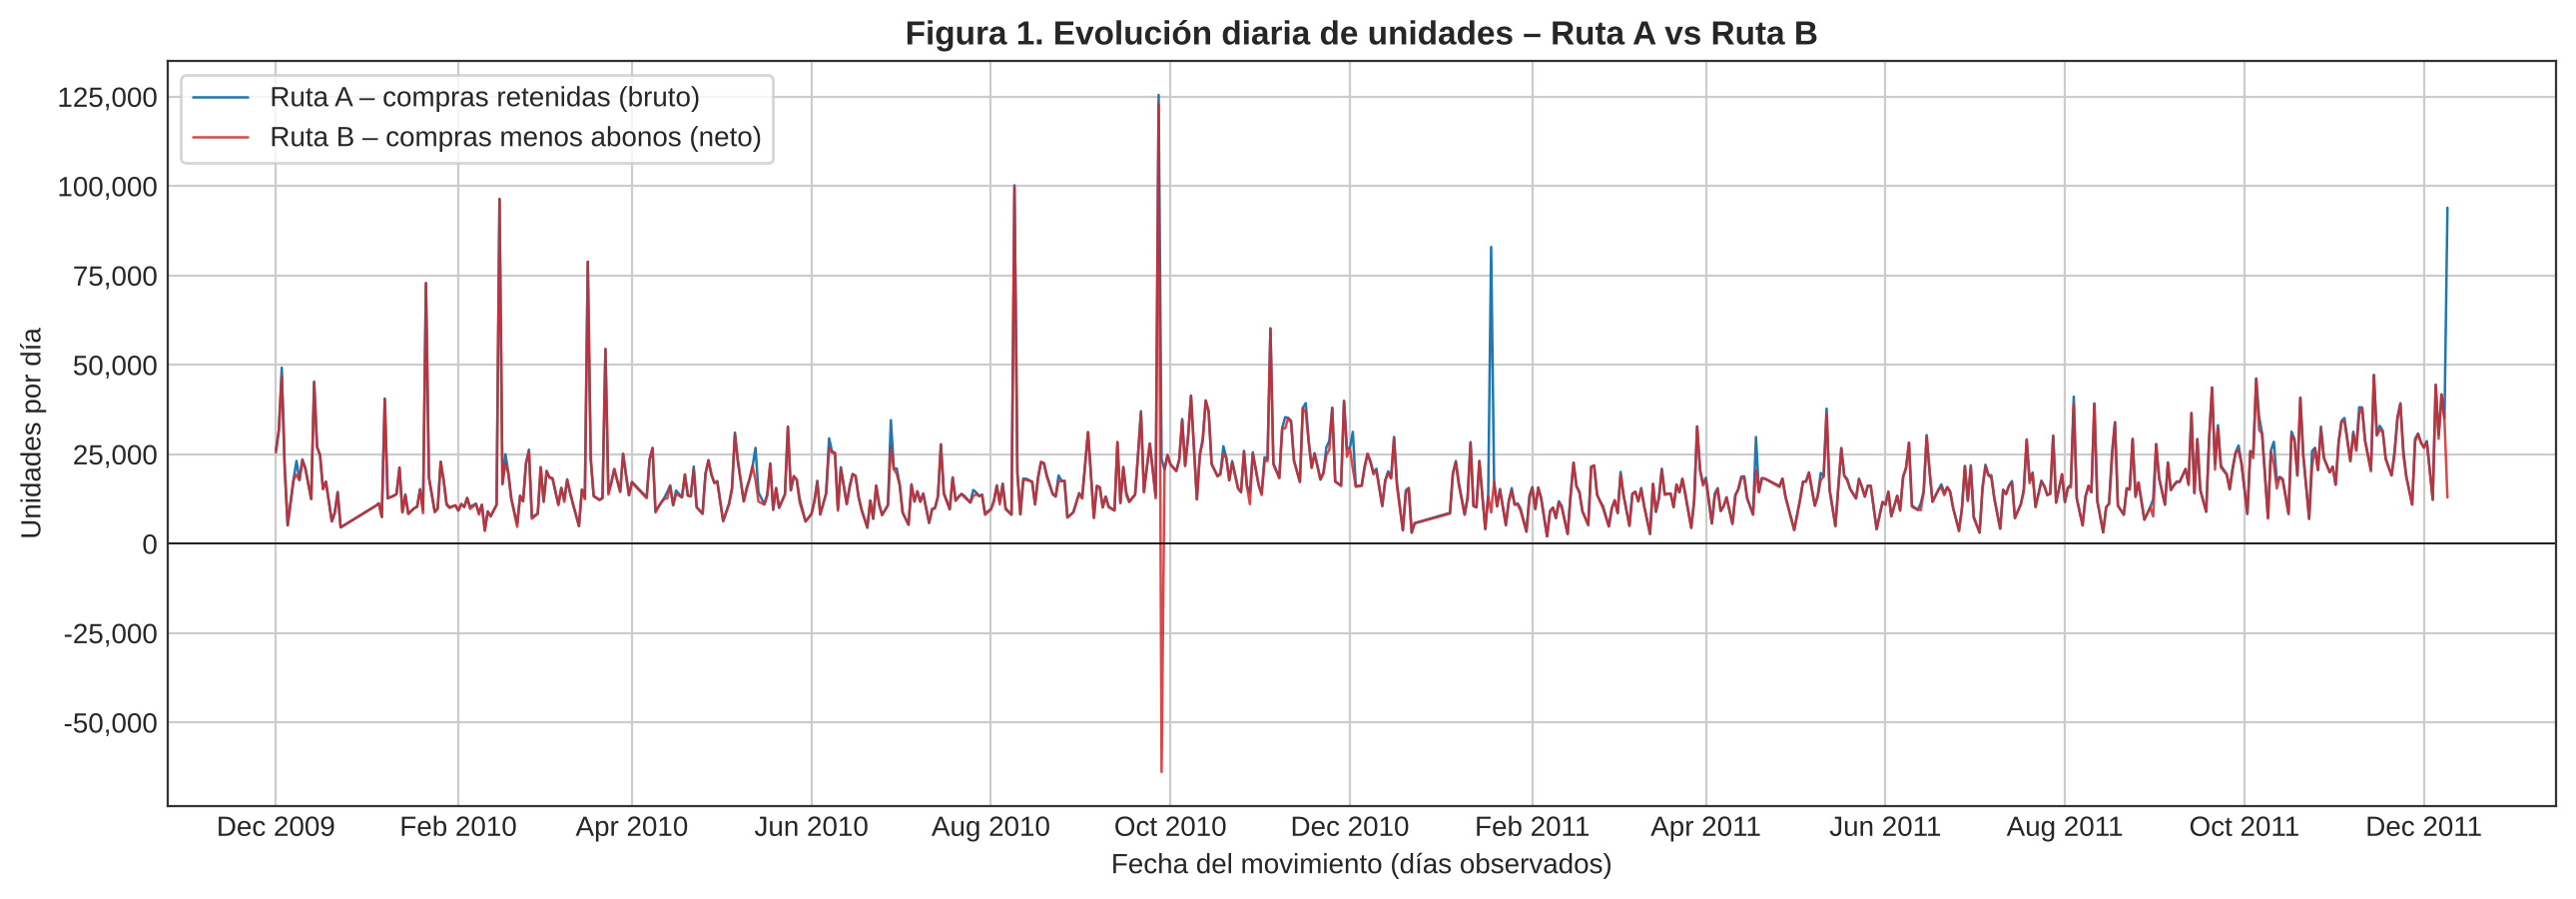

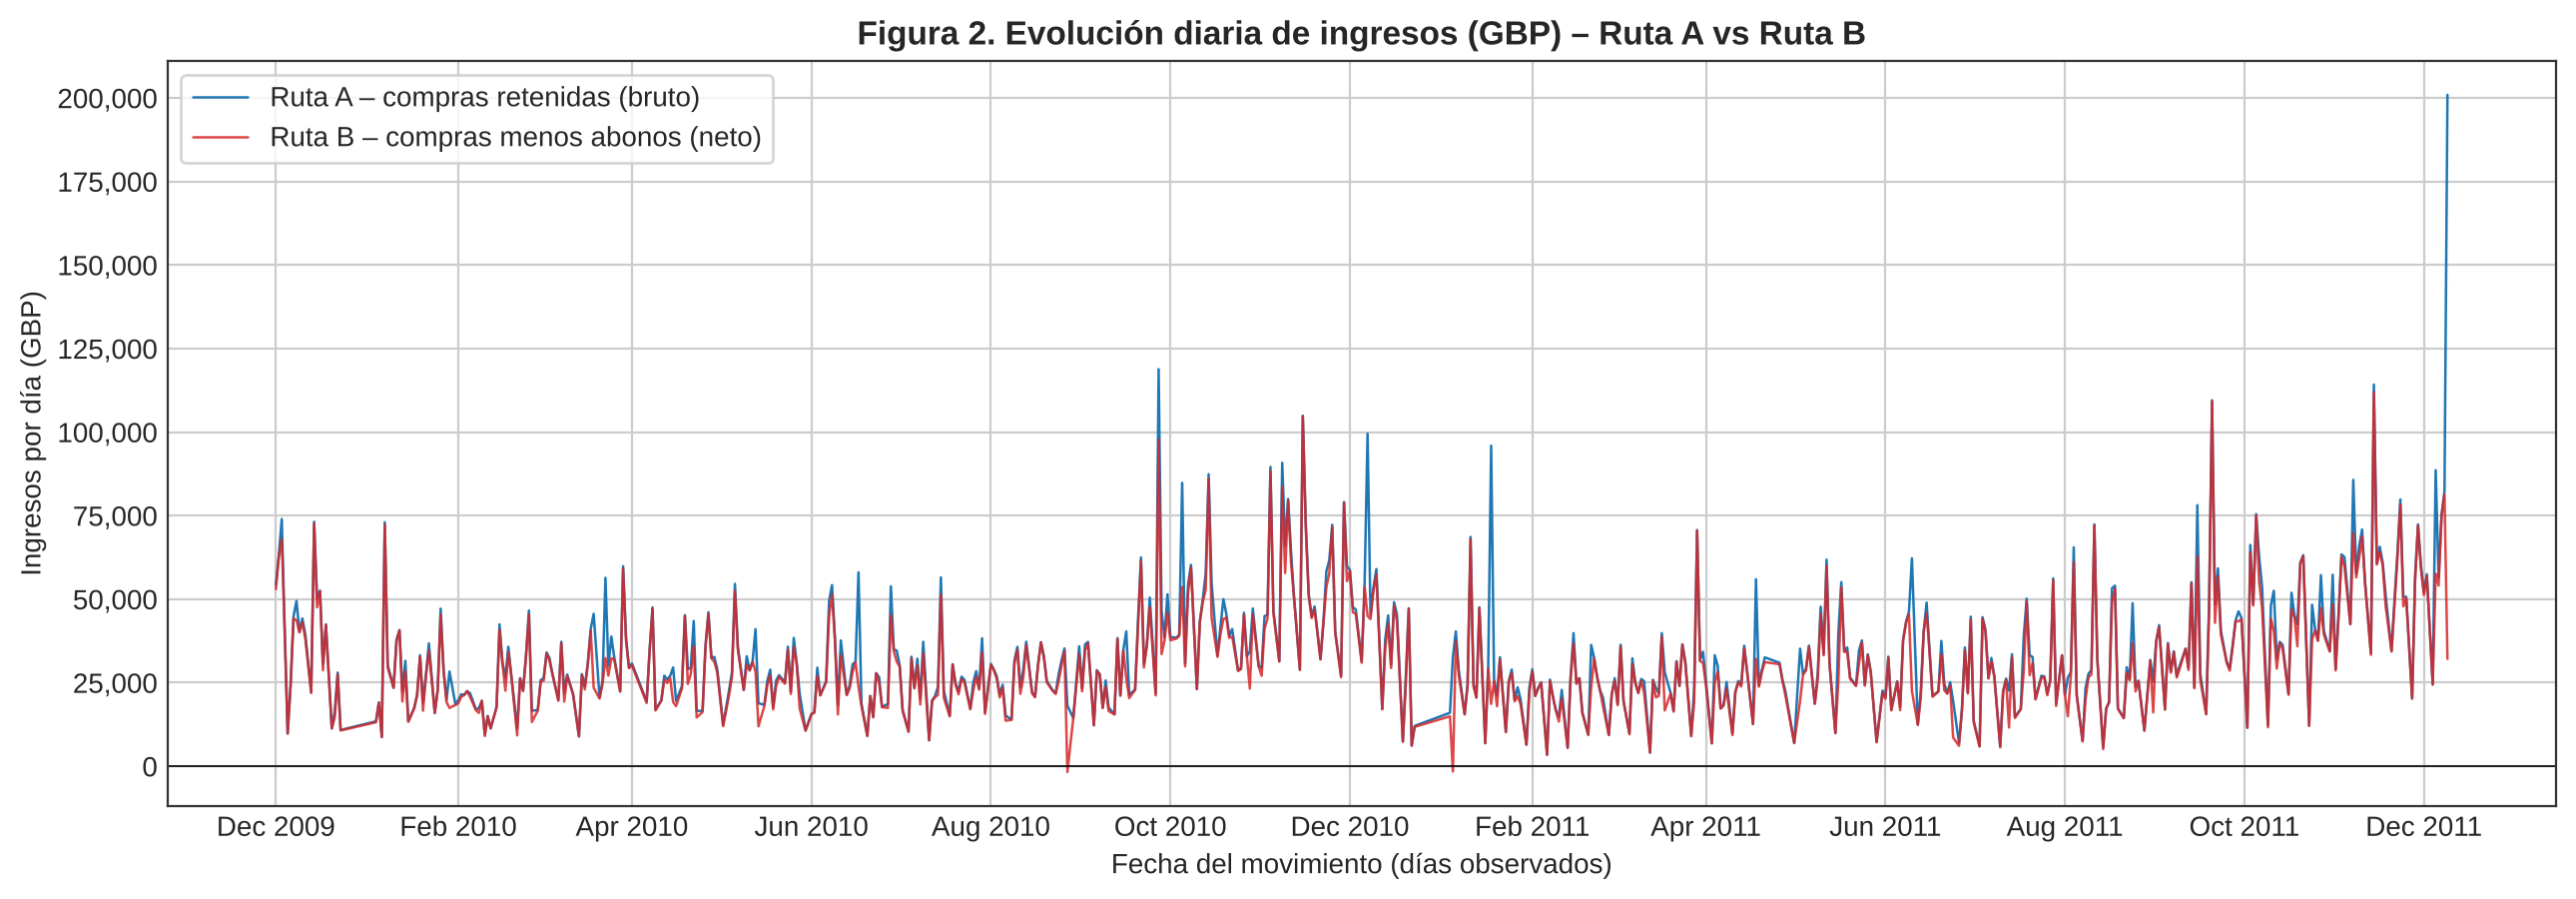

In [17]:
delta = pd.DataFrame({'dOrders': dB.TotalOrders - dA.TotalOrders, 'dUnits': dB.TotalUnits - dA.TotalUnits, 'dRevenue': dB.Revenue - dA.Revenue})
fmt_miles = mticker.FuncFormatter(lambda x, p: f'{x:,.0f}')

def serie(col, ylabel, titulo, archivo):
    fig, ax = plt.subplots(figsize=(13, 4.6), dpi=200)
    ax.plot(dA.index, dA[col], color='#1f77b4', lw=0.9, label='Ruta A – compras retenidas (bruto)')
    ax.plot(dB.index, dB[col], color='#d62728', lw=0.9, alpha=0.85, label='Ruta B – compras menos abonos (neto)')
    ax.axhline(0, color='black', lw=0.6)
    ax.set_title(titulo, fontweight='bold'); ax.set_xlabel('Fecha del movimiento (días observados)'); ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(fmt_miles); ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.legend(loc='upper left', frameon=True); fig.tight_layout(); fig.savefig(f'figures/{archivo}', bbox_inches='tight'); plt.show()

serie('TotalUnits', 'Unidades por día', 'Figura 1. Evolución diaria de unidades – Ruta A vs Ruta B', 'fig1_unidades_diarias.png')
serie('Revenue', 'Ingresos por día (GBP)', 'Figura 2. Evolución diaria de ingresos (GBP) – Ruta A vs Ruta B', 'fig2_ingresos_diarios.png')

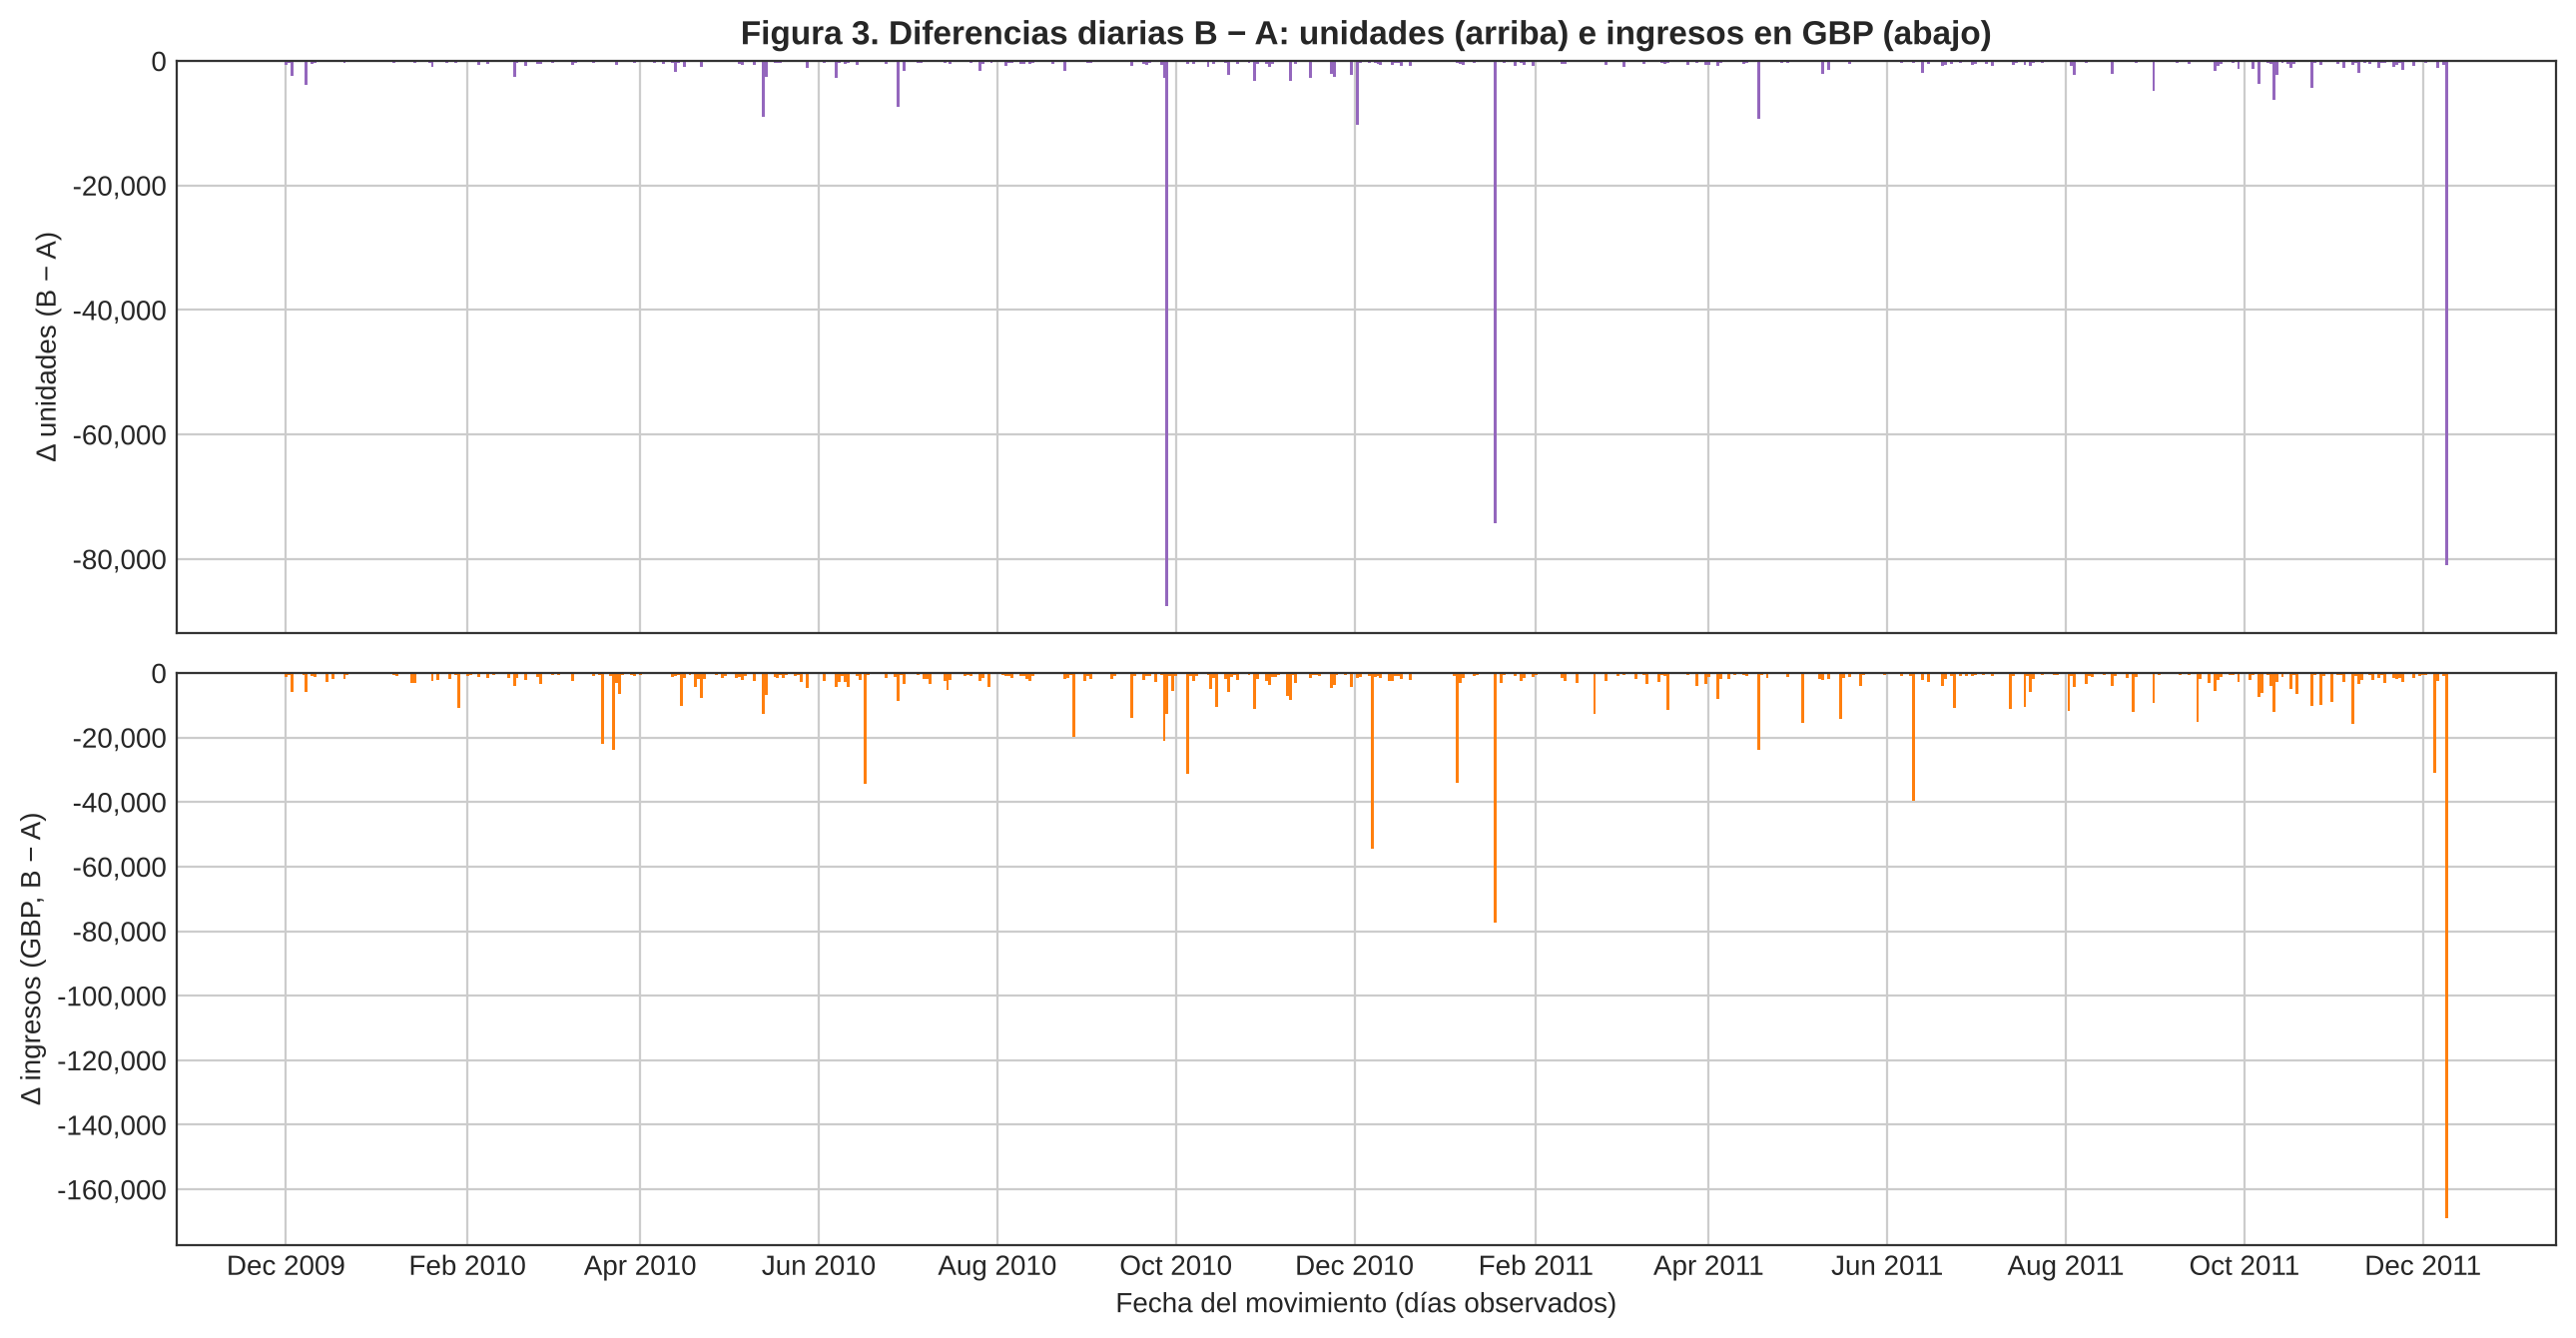

Días con Δ ≠ 0 en ingresos: 598 de 604


In [18]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 6.8), dpi=200, sharex=True)
a1.bar(delta.index, delta.dUnits, width=1.0, color='#9467bd'); a1.set_ylabel('Δ unidades (B − A)'); a1.yaxis.set_major_formatter(fmt_miles)
a1.set_title('Figura 3. Diferencias diarias B − A: unidades (arriba) e ingresos en GBP (abajo)', fontweight='bold')
a2.bar(delta.index, delta.dRevenue, width=1.0, color='#ff7f0e'); a2.set_ylabel('Δ ingresos (GBP, B − A)'); a2.yaxis.set_major_formatter(fmt_miles)
a2.set_xlabel('Fecha del movimiento (días observados)'); a2.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); a2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
for a in (a1, a2): a.axhline(0, color='black', lw=0.6)
fig.tight_layout(); fig.savefig('figures/fig3_diferencias_diarias.png', bbox_inches='tight'); plt.show()
print('Días con Δ ≠ 0 en ingresos:', int((delta.dRevenue.round(6) != 0).sum()), 'de', len(delta))

In [19]:
def pct(b, a):
    return 'No calculable' if a == 0 else 100 * (b - a) / a
tot = pd.DataFrame({
    'A': [dA.TotalOrders.sum(), dA.TotalUnits.sum(), dA.Revenue.sum()],
    'B': [dB.TotalOrders.sum(), dB.TotalUnits.sum(), dB.Revenue.sum()]},
    index=['Pedidos diarios sumados', 'Unidades', 'Ingresos en GBP'])
tot['Δ B−A'] = tot['B'] - tot['A']
tot['Δ % sobre A'] = [pct(b, a) for a, b in zip(tot['A'], tot['B'])]
display(tot)

# Comprobación: B − A = suma de abonos reconocidos
print('Δ ingresos =', round(tot.loc['Ingresos en GBP', 'Δ B−A'], 2), '| suma LineAmount abonos =', round(credits.LineAmount.sum(), 2))
print('Δ unidades =', int(tot.loc['Unidades', 'Δ B−A']), '| suma Quantity abonos =', int(credits.Quantity.sum()))
assert np.isclose(tot.loc['Ingresos en GBP', 'Δ B−A'], credits.LineAmount.sum())
assert tot.loc['Unidades', 'Δ B−A'] == credits.Quantity.sum()
R['totales'] = {i: dict(A=float(tot.loc[i, 'A']), B=float(tot.loc[i, 'B']), d=float(tot.loc[i, 'Δ B−A']),
                        p=(None if isinstance(tot.loc[i, 'Δ % sobre A'], str) else float(tot.loc[i, 'Δ % sobre A']))) for i in tot.index}

,A,B,Δ B−A,Δ % sobre A
Pedidos diarios sumados,4.007700e+04,4.007700e+04,0.00,0.000000
Unidades,1.120515e+07,1.072833e+07,-476820.00,-4.255365
Ingresos en GBP,2.047626e+07,1.901384e+07,-1462424.18,-7.142047


Δ ingresos = -1462424.18 | suma LineAmount abonos = -1462424.18
Δ unidades = -476820 | suma Quantity abonos = -476820


### Tres días con mayor diferencia monetaria absoluta y abonos que la explican

In [20]:
top3 = delta.reindex(delta.dRevenue.abs().sort_values(ascending=False).index).head(3)
top3_rows = []
for dia, r in top3.iterrows():
    ab = credits[credits.Date == dia].sort_values('LineAmount')
    print(f"\n{dia.date()}  ΔIngresos = £{r.dRevenue:,.2f}  ({pct(dB.loc[dia,'Revenue'], dA.loc[dia,'Revenue']):.2f}% sobre A = £{dA.loc[dia,'Revenue']:,.2f})  | abonos: {len(ab)} líneas en {ab.Invoice.nunique()} facturas C")
    princ = ab.head(3)[['SourceRow','Invoice','StockCode','Description','Quantity','Price','LineAmount','CustomerID','InvoiceDate']]
    display(princ)
    a_aud = audit.set_index('SourceRow').loc[princ.SourceRow, ['Status', 'LinkedInvoice', 'Reason']]
    display(a_aud)
    share = 100 * ab.head(1).LineAmount.sum() / r.dRevenue
    top3_rows.append(dict(fecha=str(dia.date()), d=float(r.dRevenue), p=float(pct(dB.loc[dia,'Revenue'], dA.loc[dia,'Revenue'])),
                          A=float(dA.loc[dia,'Revenue']), B=float(dB.loc[dia,'Revenue']), n_lineas=len(ab), n_fact=int(ab.Invoice.nunique()), share_top1=float(share),
                          principales=[dict(inv=x.Invoice, sc=x.StockCode, desc=str(x.Description), q=int(x.Quantity), p=float(x.Price), amt=float(x.LineAmount),
                                            cid=(None if pd.isna(x.CustomerID) else int(x.CustomerID)), hora=str(x.InvoiceDate),
                                            estado=audit.set_index('SourceRow').loc[x.SourceRow, 'Status'],
                                            link=str(audit.set_index('SourceRow').loc[x.SourceRow, 'LinkedInvoice'])) for x in princ.itertuples()]))
R['top3'] = top3_rows


2011-12-09  ΔIngresos = £-168,789.07  (-84.01% sobre A = £200,918.98)  | abonos: 7 líneas en 5 facturas C


,SourceRow,Invoice,StockCode,Description,Quantity,Price,LineAmount,CustomerID,InvoiceDate
1065883,1065884,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.60,16446,2011-12-09 09:27:00
1067002,1067003,C581499,M,Manual,-1,224.69,-224.69,15498,2011-12-09 10:28:00
1067176,1067177,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,10.95,-54.75,15311,2011-12-09 11:57:00


,Status,LinkedInvoice,Reason
SourceRow,,,
1065884,Conciliada,581483,Única factura previa con saldo suficiente
1067003,No conciliada,NaN,Sin compra previa del cliente para ese producto
1067177,Ambigua,NaN,Varias facturas candidatas



2011-01-18  ΔIngresos = £-77,297.25  (-80.56% sobre A = £95,947.73)  | abonos: 17 líneas en 8 facturas C


,SourceRow,Invoice,StockCode,Description,Quantity,Price,LineAmount,CustomerID,InvoiceDate
587085,587086,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.60,12346,2011-01-18 10:17:00
588173,588174,C541512,85036B,CHOCOLATE 1 WICK MORRIS BOX CANDLE,-6,4.25,-25.50,17576,2011-01-18 16:52:00
587924,587925,C541499,22325,MOBILE VINTAGE HEARTS,-3,4.95,-14.85,13693,2011-01-18 15:23:00


,Status,LinkedInvoice,Reason
SourceRow,,,
587086,Conciliada,541431,Única factura previa con saldo suficiente
588174,Conciliada,541511,Única factura previa con saldo suficiente
587925,Conciliada,536360,Única factura previa con saldo suficiente



2010-12-07  ΔIngresos = £-54,559.15  (-54.80% sobre A = £99,553.85)  | abonos: 34 líneas en 18 facturas C


,SourceRow,Invoice,StockCode,Description,Quantity,Price,LineAmount,CustomerID,InvoiceDate
519294,519295,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33,<NA>,2010-12-07 15:49:00
517953,517954,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33,<NA>,2010-12-07 15:04:00
519170,519171,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,-13474.79,<NA>,2010-12-07 15:34:00


,Status,LinkedInvoice,Reason
SourceRow,,,
519295,No conciliada,NaN,Sin cliente identificado
517954,No conciliada,NaN,Sin cliente identificado
519171,No conciliada,NaN,Sin cliente identificado


In [21]:
# Compras del mismo día que acompañan a los abonos extremos (¿cambio en compras o por abonos?)
for t in top3_rows:
    p0 = t['principales'][0]
    misma = purchases[(purchases.StockCode == p0['sc']) & (purchases.Date == pd.Timestamp(t['fecha']))]
    print(t['fecha'], p0['sc'], '- compras del mismo producto ese día:')
    display(misma[['SourceRow','Invoice','Quantity','Price','LineAmount','CustomerID','InvoiceDate']])

2011-12-09 23843 - compras del mismo producto ese día:


,SourceRow,Invoice,Quantity,Price,LineAmount,CustomerID,InvoiceDate
1065882,1065883,581483,80995,2.08,168469.6,16446,2011-12-09 09:15:00


2011-01-18 23166 - compras del mismo producto ese día:


,SourceRow,Invoice,Quantity,Price,LineAmount,CustomerID,InvoiceDate
587080,587081,541431,74215,1.04,77183.6,12346,2011-01-18 10:01:00


2010-12-07 AMAZONFEE - compras del mismo producto ese día:


,SourceRow,Invoice,Quantity,Price,LineAmount,CustomerID,InvoiceDate
517955,517956,537632,1,13541.33,13541.33,<NA>,2010-12-07 15:08:00


### Resumen mensual (contexto; diciembre 2009 y diciembre 2011 son meses parciales)

In [22]:
mA = dA.groupby(mes(dA)).agg(Pedidos=('TotalOrders', 'sum'), UnidadesA=('TotalUnits', 'sum'), IngresosA=('Revenue', 'sum'), Dias=('Revenue', 'size'))
mB = dB.groupby(mes(dB)).agg(UnidadesB=('TotalUnits', 'sum'), IngresosB=('Revenue', 'sum'))
mensual = mA.join(mB)
mensual['ΔIngresos'] = mensual.IngresosB - mensual.IngresosA
mensual['Δ%Ingresos'] = 100 * mensual['ΔIngresos'] / mensual.IngresosA
mensual['ΔUnidades'] = mensual.UnidadesB - mensual.UnidadesA
mensual['VarMensual_A_%'] = 100 * mensual.IngresosA.pct_change()
mensual['VarMensual_B_%'] = 100 * mensual.IngresosB.pct_change()
mensual['Parcial'] = ''
mensual.iloc[0, -1] = 'Parcial'; mensual.iloc[-1, -1] = 'Parcial'
display(mensual.round(2))
R['mensual'] = {str(k): {c: (v if isinstance(v, str) else float(v)) for c, v in row.items()} for k, row in mensual.iterrows()}

,Pedidos,UnidadesA,IngresosA,Dias,UnidadesB,IngresosB,ΔIngresos,Δ%Ingresos,ΔUnidades,VarMensual_A_%,VarMensual_B_%,Parcial
Date,,,,,,,,,,,,
2009-12,1682,425461,822483.95,21,415445,796648.50,-25835.45,-3.14,-10016,NaN,NaN,Parcial
2010-01,1105,390672,651155.11,24,386792,622479.50,-28675.61,-4.40,-3880,-20.83,-21.86,
2010-02,1201,381879,551504.73,24,374927,530891.80,-20612.93,-3.74,-6952,-15.30,-14.71,
2010-03,1681,526026,830915.26,27,521549,763247.24,-67668.02,-8.14,-4477,50.66,43.77,
2010-04,1462,366705,678875.25,23,360222,641521.05,-37354.20,-5.50,-6483,-18.30,-15.95,
2010-05,1500,395868,657705.50,24,379269,613270.72,-44434.78,-6.76,-16599,-3.12,-4.40,
2010-06,1645,406820,749537.31,26,391338,677073.87,-72463.44,-9.67,-15482,13.96,10.40,
2010-07,1529,337895,648810.27,26,331710,617365.48,-31444.79,-4.85,-6185,-13.44,-8.82,
2010-08,1425,472380,695251.91,26,465691,654774.39,-40477.52,-5.82,-6689,7.16,6.06,


### Riesgos adicionales detectados en las compras retenidas (aplican a ambas rutas)
Las reglas de la actividad definen como compra válida toda línea sin `C` con cantidad y precio positivos; eso incluye
movimientos que no son mercancía. Se cuantifican para informarlos sin cambiar las reglas.

In [23]:
no_merc = ['POST', 'DOT', 'M', 'C2', 'BANK CHARGES', 'AMAZONFEE', 'ADJUST', 'ADJUST2', 'D', 'S', 'B', 'CRUK', 'PADS', 'TEST001', 'TEST002', 'gift_0001_10', 'gift_0001_20', 'gift_0001_30', 'gift_0001_40', 'gift_0001_50', 'SP1002']
nm = purchases[purchases.StockCode.str.upper().isin([s.upper() for s in no_merc])]
nm_tab = nm.groupby('StockCode').agg(Lineas=('SourceRow', 'size'), Importe=('LineAmount', 'sum')).sort_values('Importe', ascending=False)
display(nm_tab.round(2))
ajuste = purchases[purchases.Invoice.str.startswith('A')]
display(ajuste[['SourceRow','Invoice','StockCode','Description','Quantity','Price','InvoiceDate']])
R['riesgos'] = dict(no_merc_lineas=int(len(nm)), no_merc_importe=float(nm.LineAmount.sum()), pct_no_merc=float(100 * nm.LineAmount.sum() / purchases.LineAmount.sum()),
                    ajuste_A=ajuste[['Invoice','StockCode','Description','Price','InvoiceDate']].astype(str).to_dict('records'),
                    sin_cliente_compras=int(purchases.CustomerID.isna().sum()), sin_cliente_importe=float(purchases[purchases.CustomerID.isna()].LineAmount.sum()),
                    abonos_sin_cliente_importe=float(credits[credits.CustomerID.isna()].LineAmount.sum()),
                    abonos_M=float(credits[credits.StockCode == 'M'].LineAmount.sum()))
print(R['riesgos'])

,Lineas,Importe
StockCode,,
M,846,339226.24
DOT,1415,309854.11
POST,1851,125682.42
AMAZONFEE,3,20467.80
C2,267,13426.00
B,1,11062.06
ADJUST,36,8897.93
ADJUST2,3,731.05
gift_0001_30,24,610.09


,SourceRow,Invoice,StockCode,Description,Quantity,Price,InvoiceDate
825443,825444,A563185,B,Adjust bad debt,1,11062.06,2011-08-12 14:50:00


{'no_merc_lineas': 4573, 'no_merc_importe': 832284.448, 'pct_no_merc': 4.064631088833863, 'ajuste_A': [{'Invoice': 'A563185', 'StockCode': 'B', 'Description': 'Adjust bad debt', 'Price': '11062.06', 'InvoiceDate': '2011-08-12 14:50:00'}], 'sin_cliente_compras': 228488, 'sin_cliente_importe': 3101456.1799999997, 'abonos_sin_cliente_importe': -377611.2, 'abonos_M': -422926.13999999996}


### Proporción del abono neto según trazabilidad
La conciliación describe trazabilidad, no reconocimiento: todos los abonos `C` documentados se reconocen en B. Se
cuantifica qué parte del importe abonado tiene vínculo según la regla.

In [24]:
audit['Importe'] = -audit['ReturnedUnits'] * audit['Price']
traz = audit.groupby('Status')['Importe'].sum().reindex(orden)
traz_pct = 100 * traz / audit['Importe'].sum()
display(pd.DataFrame({'Importe abonado GBP': traz.round(2), '% del total abonado': traz_pct.round(2)}))
R['trazabilidad'] = {s: dict(importe=float(traz[s]), pct=float(traz_pct[s])) for s in orden}
R['trazabilidad']['pct_credito_sobre_A'] = float(100 * credits.LineAmount.sum() / purchases.LineAmount.sum())

# Abonos de mercancía frente a códigos de servicio/ajuste (M, AMAZONFEE, BANK CHARGES, POST, D, ...)
cod_serv = [s.upper() for s in no_merc]
audit['Tipo'] = np.where(audit['StockCode'].str.upper().isin(cod_serv), 'Servicio/ajuste', 'Mercancía')
pv = audit.pivot_table(index='Tipo', columns='Status', values='Importe', aggfunc='sum').reindex(columns=orden).fillna(0)
pv['Total'] = pv.sum(axis=1)
pv_pct = 100 * pv[orden].div(pv['Total'], axis=0)
display(pv.round(2)); display(pv_pct.round(2))
print('Abonos sin cliente por StockCode (importe):')
display(audit[audit.CustomerID.isna()].groupby('StockCode')['Importe'].agg(['size', 'sum']).sort_values('sum', ascending=False).head(6).round(2))
R['trazabilidad']['por_tipo'] = {t: {c: float(pv.loc[t, c]) for c in pv.columns} for t in pv.index}
R['trazabilidad']['por_tipo_pct'] = {t: {c: float(pv_pct.loc[t, c]) for c in orden} for t in pv_pct.index}
R['trazabilidad']['no_conc_por_motivo'] = audit[audit.Status == 'No conciliada'].groupby('Reason')['Importe'].sum().to_dict()

,Importe abonado GBP,% del total abonado
Status,,
Conciliada,-588174.90,40.22
Ambigua,-132723.50,9.08
No conciliada,-741525.78,50.71


Status,Conciliada,Ambigua,No conciliada,Total
Tipo,,,,
Mercancía,-529604.79,-121199.3,-65691.44,-716495.53
Servicio/ajuste,-58570.11,-11524.2,-675834.34,-745928.65


Status,Conciliada,Ambigua,No conciliada
Tipo,,,
Mercancía,73.92,16.92,9.17
Servicio/ajuste,7.85,1.54,90.60


Abonos sin cliente por StockCode (importe):


,size,sum
StockCode,,
17003,1,-0.42
21703,1,-0.42
85172,1,-0.42
82580,1,-0.55
21902,1,-0.65
22436,1,-0.65


---
## Decisión y exportación de la ruta elegida
**Ruta seleccionada: B (compras menos abonos registrados).** Fundamentos (detallados en el informe):
1. Los abonos `C` son documentos comerciales explícitos con precio positivo; omitirlos (ruta A) sobrestima ingresos y
   unidades exactamente en el importe abonado.
2. B no altera pedidos ni compras: la diferencia B − A coincide al centavo con la suma de abonos reconocidos.
3. Los abonos se registran en su fecha, sin reescribir el historial, lo que permite construir RFM y recompra sin fuga
   de información.

**Limitación que se informa:** solo una parte del importe abonado tiene una factura de origen identificada según la
regla; el resto (ambiguo o no conciliado) se reconoce porque está documentado, pero su vínculo con una compra no es
trazable con los datos disponibles. `Revenue` **no** es utilidad (no hay costos).

In [25]:
RUTA = 'B'
sel = routeB if RUTA == 'B' else purchases
tp = sel[['SourceRow', 'Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'Country', 'LineAmount', 'Date', 'MovementType']].sort_values('SourceRow').copy()
tp['InvoiceDate'] = tp['InvoiceDate'].dt.strftime('%Y-%m-%d %H:%M:%S')
tp['Date'] = tp['Date'].dt.strftime('%Y-%m-%d')
tp.to_csv('outputs/transacciones_procesadas.csv', index=False)
exportable(dB if RUTA == 'B' else dA).to_csv('outputs/indicadores_diarios.csv', index=False)

# Registro de exclusiones y motivo (complemento de trazabilidad)
log = df[['SourceRow', 'Invoice', 'CommonExclusion']].dropna(subset=['CommonExclusion']).rename(columns={'CommonExclusion': 'Motivo'})
log['Etapa'] = 'Común'
la = base.loc[base.RouteA_Status != 'Compra válida', ['SourceRow', 'Invoice', 'RouteA_Status']].rename(columns={'RouteA_Status': 'Motivo'}); la['Etapa'] = 'Ruta A'
lb = base.loc[~base.RouteB_Status.isin(['Compra válida', 'Abono C reconocido']), ['SourceRow', 'Invoice', 'RouteB_Status']].rename(columns={'RouteB_Status': 'Motivo'}); lb['Etapa'] = 'Ruta B'
registro = pd.concat([log, la, lb])[['SourceRow', 'Etapa', 'Invoice', 'Motivo']].sort_values(['Etapa', 'SourceRow'])
registro.to_csv('outputs/registro_exclusiones.csv', index=False)
display(registro.groupby(['Etapa', 'Motivo']).size().rename('Líneas').to_frame())

# Verificación de reconstrucción desde el original
chk = pd.read_csv('outputs/transacciones_procesadas.csv', dtype={'Invoice': str, 'StockCode': str})
assert len(chk) == nB_keep and chk.SourceRow.is_unique
assert chk.CustomerID.isna().sum() == sel.CustomerID.isna().sum()
assert set(chk.MovementType) == {'Purchase', 'Credit'}
print('transacciones_procesadas.csv:', chk.shape, chk.MovementType.value_counts().to_dict())
print('Base común = conservadas B + excluidas B (registro):', nB_keep + int((registro.Etapa == 'Ruta B').sum()), '=', N_BASE)
R['export'] = dict(ruta=RUTA, filas_tp=len(chk), cols=list(chk.columns), mov=chk.MovementType.value_counts().to_dict(), registro=len(registro))
with open('outputs/resultados_informe.json', 'w', encoding='utf-8') as fh:
    json.dump(R, fh, ensure_ascii=False, indent=1, default=str)
chk.head()

Líneas
Etapa  Motivo                                    
Común  Duplicado exacto (copia adicional)   34335
Ruta A Prefijo C                            19104
       Price <= 0                            2626
       Quantity <= 0                         3393
Ruta B Excepción C (Q>=0 o P<=0)                1
       Negativo sin C                        3393
       Precio no positivo sin C              2626

transacciones_procesadas.csv: (1027016, 12) {'Purchase': 1007913, 'Credit': 19103}
Base común = conservadas B + excluidas B (registro): 1033036 = 1033036


,SourceRow,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,LineAmount,Date,MovementType
0,1,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12-01,Purchase
1,2,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01,Purchase
2,3,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12-01,Purchase
3,4,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009-12-01,Purchase
4,5,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12-01,Purchase


### Archivos generados
| Archivo | Contenido |
|---|---|
| `outputs/transacciones_procesadas.csv` | Ruta B: 8 columnas originales (`Customer ID` → `CustomerID`), `SourceRow`, `LineAmount`, `Date`, `MovementType` (Purchase/Credit) |
| `outputs/indicadores_diarios.csv` | Ruta B: `Date` (AAAA-MM-DD), `TotalOrders`, `TotalUnits`, `Revenue` |
| `outputs/indicadores_diarios_comparacion.csv` | Ambas rutas con columna `Route` |
| `outputs/auditoria_conciliacion_abonos.csv` | Complemento: una fila por abono C con candidatas, vínculo, estado y motivo |
| `outputs/registro_exclusiones.csv` | Complemento: `SourceRow` excluido por etapa y motivo |
| `outputs/resultados_informe.json` | Cifras usadas en el informe |